# Testing Attention on Block Task
The purpose of this notebook is to train and test the simple attention head on the block task.

## Import

In [1]:
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from relational_attention.tasks import BlockComparisonDataset
from relational_attention.models import SelfAttentionHead, RelationalAttentionHead, AttentionClassifier

In [2]:
torch.manual_seed(42)

## Build task

In [3]:
# Parameters
num_samples = 1000
num_vectors = 4
vector_len = 6

In [4]:
dataset = BlockComparisonDataset(num_samples, num_vectors, vector_len)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

## Build and Train model

### Simple attention

In [5]:
model_self_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=vector_len, context_size=num_vectors, attn_cls=SelfAttentionHead
)

In [6]:
epochs = 250
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

In [7]:
loss_self_attn = []

for epoch in range(epochs):
    total_loss = 0
    for X, y in loader:
        optimizer.zero_grad()
        preds = model_self_attn(X)
        loss = loss_fn(preds, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: loss={total_loss/len(loader):.4f}")
    loss_self_attn.append(total_loss/len(loader))

Epoch 0: loss=0.6948
Epoch 10: loss=0.5954
Epoch 20: loss=0.4296
Epoch 30: loss=0.3705
Epoch 40: loss=0.3565
Epoch 50: loss=0.3527
Epoch 60: loss=0.3516
Epoch 70: loss=0.3504
Epoch 80: loss=0.3492
Epoch 90: loss=0.3508
Epoch 100: loss=0.3494
Epoch 110: loss=0.3497
Epoch 120: loss=0.3478
Epoch 130: loss=0.3558
Epoch 140: loss=0.3495
Epoch 150: loss=0.3488
Epoch 160: loss=0.3495
Epoch 170: loss=0.3485
Epoch 180: loss=0.3490
Epoch 190: loss=0.3476
Epoch 200: loss=0.3517
Epoch 210: loss=0.3501
Epoch 220: loss=0.3475
Epoch 230: loss=0.3476
Epoch 240: loss=0.3485


### Abstract attention

In [8]:
model_abstract_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=vector_len, context_size=num_vectors, attn_cls=RelationalAttentionHead
)

In [9]:
epochs = 250
optimizer = torch.optim.Adam(model_abstract_attn.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

In [10]:
loss_abstract_attn = []

for epoch in range(epochs):
    total_loss = 0
    for X, y in loader:
        optimizer.zero_grad()
        preds = model_abstract_attn(X)
        loss = loss_fn(preds, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: loss={total_loss/len(loader):.4f}")
    loss_abstract_attn.append(total_loss/len(loader))

Epoch 0: loss=0.6965
Epoch 10: loss=0.6797
Epoch 20: loss=0.1188
Epoch 30: loss=0.0216
Epoch 40: loss=0.0102
Epoch 50: loss=0.0059
Epoch 60: loss=0.0036
Epoch 70: loss=0.0023
Epoch 80: loss=0.0015
Epoch 90: loss=0.0010
Epoch 100: loss=0.0007
Epoch 110: loss=0.0005
Epoch 120: loss=0.0003
Epoch 130: loss=0.0002
Epoch 140: loss=0.0001
Epoch 150: loss=0.0001
Epoch 160: loss=0.0001
Epoch 170: loss=0.0000
Epoch 180: loss=0.0000
Epoch 190: loss=0.0000
Epoch 200: loss=0.0000
Epoch 210: loss=0.0000
Epoch 220: loss=0.0000
Epoch 230: loss=0.0000
Epoch 240: loss=0.0000


### Linear abstract attention

In [11]:
model_linear_attn = AttentionClassifier(
    embed_dim=vector_len, head_dim=vector_len, context_size=num_vectors, attn_cls=RelationalAttentionHead, linear=True
)

In [12]:
epochs = 250
optimizer = torch.optim.Adam(model_linear_attn.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

In [13]:
loss_linear_attn = []

for epoch in range(epochs):
    total_loss = 0
    for X, y in loader:
        optimizer.zero_grad()
        preds = model_linear_attn(X)
        loss = loss_fn(preds, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: loss={total_loss/len(loader):.4f}")
    loss_linear_attn.append(total_loss/len(loader))

Epoch 0: loss=0.6955
Epoch 10: loss=0.0079
Epoch 20: loss=0.0010
Epoch 30: loss=0.0004
Epoch 40: loss=0.0002
Epoch 50: loss=0.0001
Epoch 60: loss=0.0001
Epoch 70: loss=0.0000
Epoch 80: loss=0.0000
Epoch 90: loss=0.0000
Epoch 100: loss=0.0000
Epoch 110: loss=0.0000
Epoch 120: loss=0.0000
Epoch 130: loss=0.0000
Epoch 140: loss=0.0000
Epoch 150: loss=0.0000
Epoch 160: loss=0.0000
Epoch 170: loss=0.0000
Epoch 180: loss=0.0000
Epoch 190: loss=0.0000
Epoch 200: loss=0.0000
Epoch 210: loss=0.0000
Epoch 220: loss=0.0000
Epoch 230: loss=0.0000
Epoch 240: loss=0.0000


In [14]:
metadata = {
    "embed_dim": vector_len,
    "head_dim": vector_len,
    "context_size": num_vectors,
    "pooling": "flatten",
    "num_epochs": epochs,
    "train_loss_curve": loss_linear_attn,  # if available
}

torch.save({
    "model_state": model_linear_attn.state_dict(),
    "metadata": metadata,
}, "../../data/linear_relational_attention_block_classifier_full.pt")

## Plot training dynamics

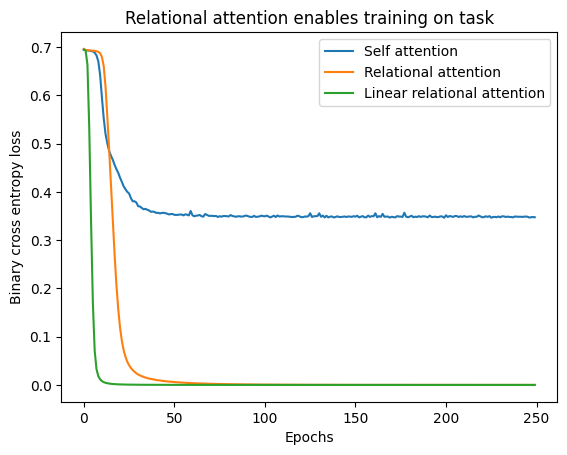

In [15]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_abstract_attn, label='Relational attention')
plt.plot(loss_linear_attn, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Relational attention enables training on task')
plt.legend()
plt.show()